# Backlog v1 — span 001 evidence

E00 and pilots H01/H04/H09/H11, fixed grouped partitions and a predeclared budget.
This notebook reads aggregate artifacts only. Its tables reflect available evidence,
including incomplete/failed runs. See docs/SPAN_001_PROTOCOL.md for controls and
docs/SPAN_001_RESULTS.md for the current outcome. No new official score is inferred.


None of the predeclared pilots justified promotion. The best new point estimate was random_attention at 0.97609 versus deployed LoRA 0.97635; gain 0.000258, interval [-0.003574, +0.004205], below the predeclared 0.005 useful-gain threshold. Our official Kaggle score remains 0.97025; this span made no submission.

In [1]:
import json, os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
repo=Path.cwd()
if repo.name=='notebooks':repo=repo.parent
directory=repo/'results/span_001'
plan=json.loads((directory/'span_plan.json').read_text())
display(pd.Series(plan,name='predeclared span plan').to_frame())
inventory=json.loads((directory/'artifact_inventory.json').read_text())
display(pd.Series(inventory,name='artifact inventory').to_frame())


,predeclared span plan
span,1
started_at,2026-11-03T10:06:28+00:00
deadline,2026-11-05T10:06:28+00:00
gpu_session_seconds_cap,43200
quota_used_at_start,40562.245
quota_reserved_at_start,0.0
focus,"[E00, H01, H09, H04, H11]"
seed,20261118
dev_rows,1024
feature_fit_rows,4096


,artifact inventory
split_ids_sha256,066f7ab82a3f14464ce0ef67bfd8b8b34ed190679bfea5...
sample_ids_sha256,716c065f583d45ef6028034e77349cf245b849abbf3f6d...
selection_sha256,68a097c19cabe454c99925cc41153fd9cfb4b5a35bc3f6...
baseline_predictions_sha256,5b2522d2be7fed1d490ebe6135afe97fe3863339d8c34a...
baseline_adapter_expected_sha256,8afc09d728698c7bcd02e47f9d427166b4b07b3644c848...
baseline_adapter_local_present,True
baseline_adapter_local_sha256,8afc09d728698c7bcd02e47f9d427166b4b07b3644c848...
baseline_kernel,arseniytrushin/llm-preference-qwen3-4b-train-002
baseline_kernel_version,1
baseline_temperature,0.72206


The exact sample IDs are private heavy artifacts, with their digest recorded
above. All fit rows are original training rows; the 1,024 evaluation rows are in the
existing development partition. They are exploratory because the project previously
inspected this data. No confirmation labels are evaluated for this span.


In [2]:
reports={name:json.loads(path.read_text()) for name in ('reward','joint')
         if (path:=directory/(name+'_results.json')).exists()}
if reports:
    reference=next(iter(reports.values()))
    display(pd.DataFrame([{'reference':'Frozen deployment temperature',**reference['baseline_deployed']},
                          {'reference':'Matched group-cross-fitted temperature',**reference['baseline_crossfit_temperature']}])
            [['reference','rows','log_loss','accuracy','tie_auc']])
rows=[]
for stage,report in reports.items():
    for item in report['models']:
        gain=item['gain_vs_deployed']
        rows.append({'stage':stage,'model':item['name'],
                     'raw_loss':item['raw']['log_loss'],
                     'crossfit_calibrated_loss':item['crossfit_temperature']['log_loss'],
                     'accuracy':item['crossfit_temperature']['accuracy'],
                     'tie_auc':item['crossfit_temperature']['tie_auc'],
                     'tie_recall':item['crossfit_temperature']['class_recall'][2],
                     'gain_vs_deployed':gain['gain'],'gain_interval_low':gain['interval_95'][0],
                     'gain_interval_high':gain['interval_95'][1],
                     'gain_vs_matched_crossfit':item['gain_vs_crossfit_baseline']['gain']})
table=pd.DataFrame(rows)
if len(table):display(table.round(6))
else:print('Model quality measurements are not available yet; preparation and live observations follow.')
class_rows=[]
for report in reports.values():
    for item in report['models']:
        values=item['crossfit_temperature']
        class_rows.append({'model':item['name'],'tie_precision':values['tie_precision'],
            'mean_entropy':values.get('mean_predictive_entropy',np.nan),
            **{f'loss_{name}':values['class_loss'][i] for i,name in enumerate(['A','B','tie'])},
            **{f'recall_{name}':values['class_recall'][i] for i,name in enumerate(['A','B','tie'])}})
if class_rows:display(pd.DataFrame(class_rows).round(6))


,reference,rows,log_loss,accuracy,tie_auc
0,Frozen deployment temperature,1024,0.976350,0.522461,0.659566
1,Matched group-cross-fitted temperature,1024,0.977521,0.522461,0.659244


,stage,model,raw_loss,crossfit_calibrated_loss,accuracy,tie_auc,tie_recall,gain_vs_deployed,gain_interval_low,gain_interval_high,gain_vs_matched_crossfit
0,reward,reward_coupled,1.011246,1.015571,0.506836,0.593023,0.356037,-0.039221,-0.068212,-0.011427,-0.038050
1,joint,tie_probability_coupled,0.976419,0.977742,0.512695,0.657301,0.393189,-0.001392,-0.005369,0.002581,-0.000221
2,joint,tie_rich_coupled,0.983301,0.984215,0.516602,0.648675,0.414861,-0.007865,-0.018611,0.002741,-0.006694
3,joint,tie_rich_factorized,0.982717,0.983535,0.516602,0.650954,0.414861,-0.007185,-0.017592,0.003184,-0.006014
4,joint,random_attention,0.977414,0.976092,0.520508,0.661501,0.371517,0.000258,-0.003574,0.004205,0.001429
5,joint,random_all_linear,0.978372,0.976664,0.518555,0.660719,0.349845,-0.000314,-0.004922,0.004318,0.000857
6,joint,paired_attention,0.979600,0.978442,0.515625,0.658060,0.309598,-0.002092,-0.008710,0.004567,-0.000921
7,joint,paired_consistency,0.980402,0.979198,0.520508,0.658396,0.303406,-0.002848,-0.010301,0.004569,-0.001677


,model,tie_precision,mean_entropy,loss_A,loss_B,loss_tie,recall_A,recall_B,recall_tie
0,reward_coupled,0.425926,1.010249,0.926345,0.992861,1.134877,0.594118,0.559557,0.356037
1,tie_probability_coupled,0.481061,0.976507,0.924574,0.933689,1.082944,0.576471,0.559557,0.393189
2,tie_rich_coupled,0.475177,0.983134,0.941852,0.935694,1.083037,0.564706,0.562327,0.414861
3,tie_rich_factorized,0.480287,0.982507,0.941852,0.935213,1.081418,0.567647,0.559557,0.414861
4,random_attention,0.497925,0.974706,0.918141,0.926693,1.092302,0.594118,0.584488,0.371517
5,random_all_linear,0.506726,0.975269,0.908728,0.916903,1.114967,0.602941,0.590028,0.349845
6,paired_attention,0.507614,0.977015,0.893463,0.901074,1.154364,0.614706,0.606648,0.309598
7,paired_consistency,0.529730,0.977758,0.885362,0.892704,1.174640,0.620588,0.620499,0.303406


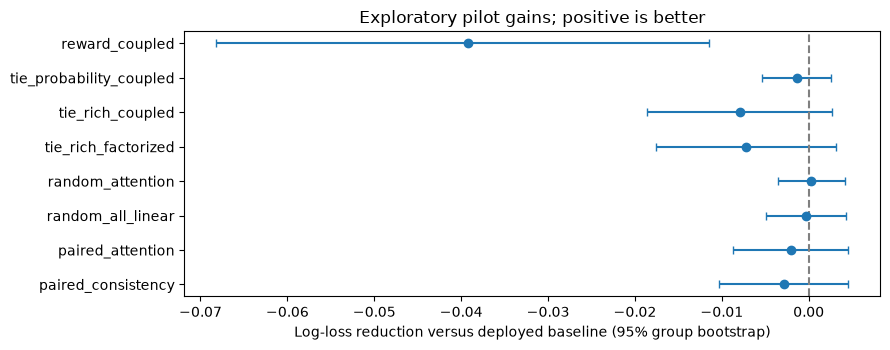

In [3]:
if len(table):
    fig,ax=plt.subplots(figsize=(9,max(3,len(table)*.45)))
    positions=np.arange(len(table))
    low=table.gain_vs_deployed-table.gain_interval_low
    high=table.gain_interval_high-table.gain_vs_deployed
    ax.errorbar(table.gain_vs_deployed,positions,xerr=np.vstack([low,high]),fmt='o',capsize=3)
    ax.axvline(0,color='gray',linestyle='--')
    ax.set(yticks=positions,yticklabels=table.model,xlabel='Log-loss reduction versus deployed baseline (95% group bootstrap)',
           title='Exploratory pilot gains; positive is better')
    ax.invert_yaxis();fig.tight_layout()
    figures=Path(os.environ.get('ARENA_DATA_DIR',str(Path.home()/'database/llm_classification_finetuning')))/'runs/span_001/figures'
    figures.mkdir(parents=True,exist_ok=True)
    fig.savefig(figures/'pilot_gains.png',dpi=180,bbox_inches='tight')
    fig.savefig(figures/'pilot_gains.svg',bbox_inches='tight')
    plt.show()


In [4]:
if 'joint' in reports:
    display(pd.DataFrame(reports['joint'].get('primary_comparisons',{})).T)
    order_rows=[]
    for model in reports['joint']['models']:
        if model.get('raw_order'):
            order_rows.append({'model':model['name'],**model['raw_order'],
                'single_original_raw_loss':model['original_order_uncalibrated']['log_loss'],
                'single_swapped_raw_loss':model['aligned_swapped_order_uncalibrated']['log_loss'],
                'swap_averaged_raw_loss':model['raw']['log_loss'],
                'order_disagreement_reduction_vs_frozen':model.get('order_disagreement_reduction_vs_frozen')})
        if model['details'].get('numerical_audit'):
            print(model['name'],'numerical / exposure audit:')
            display(pd.Series({key:model['details'][key] for key in ('steps','canonical_exposures',
                'non_padding_tokens_seen','training_seconds','peak_gpu_bytes','numerical_audit',
                'adapter_weight_audit')}).to_frame())
    if order_rows:display(pd.DataFrame(order_rows))
    print('Frozen baseline reproduction:',reports['joint'].get('frozen_baseline_reproduction'))
if (directory/'reward_diagnostics.json').exists():
    print('H01 descriptive winner/tie decomposition; no hybrid was evaluated:')
    display(pd.Series(json.loads((directory/'reward_diagnostics.json').read_text())).to_frame())
if (directory/'retention.json').exists():
    retention=json.loads((directory/'retention.json').read_text())
    display(pd.DataFrame([{'tokenizer':name,'sample':split,
        'rows':values['rows'],'any_field_clipped_fraction':values['any_field_clipped_fraction'],
        **{'retained_'+key:value for key,value in values['corpus_content_retained_fraction'].items()}}
        for name,entry in retention['tokenizers'].items() for split,values in entry['samples'].items()]))


,gain,interval_95,groups,rows,replicates,training_comparability,order_disagreement_reduction
H04,-0.000573,"[-0.001623, 0.000478]",990,1024,2000,"{'matched': True, 'mismatches': [], 'unverifie...","{'gain': -0.001953125, 'interval_95': ['-0.013..."
H09,-0.000755,"[-0.001716, 0.000186]",990,1024,2000,"{'matched': True, 'mismatches': [], 'unverifie...","{'gain': 0.00390625, 'interval_95': ['-0.00489..."
H11_factorization,0.00068,"[-0.000913, 0.002187]",990,1024,2000,NaN,NaN
H11_extra_features_coupled,-0.006473,"[-0.015662, 0.002966]",990,1024,2000,NaN,NaN
H11_extra_features,-0.005793,"[-0.014786, 0.003504]",990,1024,2000,NaN,NaN


random_attention numerical / exposure audit:


,0
steps,64
canonical_exposures,2048
non_padding_tokens_seen,1186094
training_seconds,1740.714444
peak_gpu_bytes,5799616000
numerical_audit,{'method': 'Pinned transformers 5.22.1 cosine ...
adapter_weight_audit,"{'all_finite': True, 'tensors': 289, 'sha256':..."


random_all_linear numerical / exposure audit:


,0
steps,64
canonical_exposures,2048
non_padding_tokens_seen,1186094
training_seconds,2062.522259
peak_gpu_bytes,5798324736
numerical_audit,{'method': 'Pinned transformers 5.22.1 cosine ...
adapter_weight_audit,"{'all_finite': True, 'tensors': 505, 'sha256':..."


paired_attention numerical / exposure audit:


... (3 outputs left out)

,model,decision_disagreement,mean_probability_l1,second_position_advantage,single_original_raw_loss,single_swapped_raw_loss,swap_averaged_raw_loss,order_disagreement_reduction_vs_frozen
0,random_attention,0.286133,0.223093,0.054738,0.989811,0.988129,0.977414,"{'gain': 0.068359375, 'interval_95': ['0.04610..."
1,random_all_linear,0.288086,0.216699,0.049246,0.990007,0.988235,0.978372,"{'gain': 0.06640625, 'interval_95': ['0.043306..."
2,paired_attention,0.265625,0.196946,0.002430,0.990132,0.986547,0.979600,"{'gain': 0.0888671875, 'interval_95': ['0.0587..."
3,paired_consistency,0.261719,0.194176,-0.002927,0.990697,0.986945,0.980402,"{'gain': 0.0927734375, 'interval_95': ['0.0612..."


Frozen baseline reproduction: {'mean_absolute_probability_error': 0.00024002480673323418, 'max_absolute_probability_error': 0.004872723018787384}
H01 descriptive winner/tie decomposition; no hybrid was evaluated:


,0
decisive_rows,701
baseline_conditional_winner_accuracy,0.697575
reward_conditional_winner_accuracy,0.696148
conditional_winner_gain,"{'gain': -0.012320358743885767, 'interval_95':..."
interpretation,Descriptive decomposition of the declared H01 ...
head_direction_weight,1.045112


,tokenizer,sample,rows,any_field_clipped_fraction,retained_prompt,retained_response_a,retained_response_b
0,baseline,dev,1024,0.196289,0.665592,0.838981,0.838261
1,baseline,feature_fit,4096,0.196045,0.625494,0.823866,0.816989
2,baseline,training_pilot,2048,0.195801,0.601353,0.813177,0.825140
3,reward,dev,1024,0.196289,0.665592,0.838762,0.838261
4,reward,feature_fit,4096,0.196045,0.625494,0.823649,0.816989
5,reward,training_pilot,2048,0.195801,0.601353,0.812955,0.825140


Class-prevalence-weighted decomposition; descriptive contributions sum to overall gain:


,model,A_gain,B_gain,tie_gain,overall_gain
0,random_attention,0.009907,0.010659,-0.020308,0.000258
1,random_all_linear,0.013033,0.014110,-0.027457,-0.000314
2,paired_attention,0.018101,0.019691,-0.039884,-0.002092
3,paired_consistency,0.020791,0.022641,-0.046280,-0.002848


,model,mean_tie_probability,predicted_tie_fraction,tie_auc
0,tie_probability_coupled,0.313555,0.257812,0.657301
1,tie_rich_coupled,0.314961,0.275391,0.648675
2,tie_rich_factorized,0.315288,0.272461,0.650954
3,random_attention,0.309636,0.235352,0.661501
4,random_all_linear,0.302861,0.217773,0.660719
5,paired_attention,0.292066,0.192383,0.658060
6,paired_consistency,0.286143,0.180664,0.658396


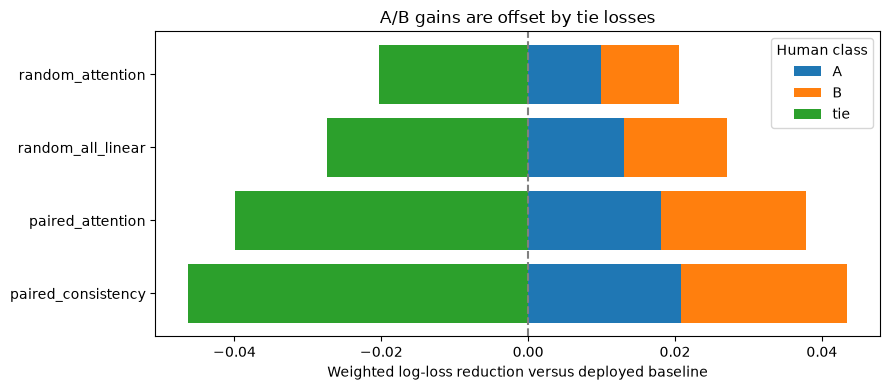

Frozen-feature runtime: [{'rank': 0, 'rows': 2560, 'complete': True, 'seconds': 2491.981291861, 'peak_gpu_bytes': 5347013120}, {'rank': 1, 'rows': 2560, 'complete': True, 'seconds': 2570.363272214, 'peak_gpu_bytes': 5347340800}]
Interpretation limits:
- All development findings are exploratory on previously inspected rows; intervals condition on fitted predictions and do not provide a multiple-comparison guarantee.
- Fresh-adapter pilots used 64 nominal cycles, with 61 reconstructed accepted updates, rather than full training.
- Processed tokens include AMP-skipped cycles. Individual skipped-cycle identities were not instrumented.
- Random and paired arms differ in canonical coverage and processed tokens; only the declared within-regime contrasts are matched.
- H11 is a frozen-feature head pilot with training-only inner selection; its backbone saw the original training partition.
- Per-class contributions are descriptive point estimates, not independent causal effects or class-specific

In [5]:
if (directory/'joint_diagnostics.json').exists():
    diagnostic=json.loads((directory/'joint_diagnostics.json').read_text())
    tradeoffs=[row for row in diagnostic['models'] if row['raw_order'] is not None]
    print('Class-prevalence-weighted decomposition; descriptive contributions sum to overall gain:')
    display(pd.DataFrame([{'model':row['model'],
        **dict(zip(['A_gain','B_gain','tie_gain'],row['weighted_class_loss_gain'])),
        'overall_gain':row['overall_gain']} for row in tradeoffs]))
    display(pd.DataFrame([{'model':row['model'],'mean_tie_probability':row['mean_tie_probability'],
        'predicted_tie_fraction':row['predicted_tie_fraction'],'tie_auc':row['tie_auc']}
        for row in diagnostic['models']]))
    values=np.array([row['weighted_class_loss_gain'] for row in tradeoffs])
    fig,ax=plt.subplots(figsize=(9,4))
    positive=np.zeros(len(values));negative=np.zeros(len(values))
    for i,label in enumerate(['A','B','tie']):
        part=values[:,i]
        ax.barh(np.arange(len(values)),part,left=np.where(part>=0,positive,negative),label=label)
        positive+=np.maximum(part,0);negative+=np.minimum(part,0)
    ax.axvline(0,color='gray',linestyle='--')
    ax.set(yticks=np.arange(len(values)),yticklabels=[row['model'] for row in tradeoffs],
        xlabel='Weighted log-loss reduction versus deployed baseline',title='A/B gains are offset by tie losses')
    ax.invert_yaxis();ax.legend(title='Human class');fig.tight_layout()
    fig.savefig(figures/'class_loss_tradeoffs.png',dpi=180,bbox_inches='tight')
    fig.savefig(figures/'class_loss_tradeoffs.svg',bbox_inches='tight')
    plt.show()
    print('Frozen-feature runtime:',diagnostic['feature_runtime'])
    print('Interpretation limits:')
    for text in diagnostic['limitations']:print('-',text)


Head regularization and representation fitting use training-only grouped inner
folds. New probability calibration is cross-fitted by development prompt group.
The JSON records a matched cross-fitted baseline as well as the historically fitted
deployment baseline. Backbones can have unknown public-data exposure; our original
frozen classifier saw its full original training partition, so head-selection inner
folds are not independent backbone OOF experiments. Report all contrasts and avoid
interpreting these intervals as proof of untouched generalization.


In [6]:
jobs=[]
for path in sorted((directory/'jobs').glob('*/controller_state.json')):
    state=json.loads(path.read_text())
    intent_path=path.parent/'push_intent.json'
    intent=json.loads(intent_path.read_text()) if intent_path.exists() else {}
    quota_path=path.parent/'quota.json'
    quota=json.loads(quota_path.read_text()) if quota_path.exists() else {}
    jobs.append({'job':path.parent.name,'observed_stage':state.get('stage'),
                 'observed_status':state.get('status'),'snapshot_utc':state.get('utc'),
                 'version':state.get('version'),'session_ceiling_seconds':intent.get('max_session_seconds'),
                 'quota_used_snapshot':quota.get('used_seconds')})
display(pd.DataFrame(jobs))
print('These are dated observations, not a new live job query.')
if (directory/'terminal_audit.json').exists():
    audit=json.loads((directory/'terminal_audit.json').read_text())
    display(pd.DataFrame(audit['jobs']))
    print('Final charged session-hours:',audit['span_gpu_session_hours'],
        'cap:',audit['gpu_session_seconds_cap']/3600,'reserved seconds:',audit['quota']['reserved_seconds'])
elif jobs:
    charges=[x['quota_used_snapshot'] for x in jobs if x['quota_used_snapshot'] is not None]
    if charges:print('Charged quota increase at latest snapshot:',max(charges)-plan['quota_used_at_start'],'seconds; unfinished use may not be posted yet.')
display(json.loads((directory/'preflight.json').read_text()))
progress_path=directory/'live_progress_joint.json'
if progress_path.exists():
    progress=json.loads(progress_path.read_text())
    print('Pinned joint version:',progress['version'],'status observed at:',progress['status_observed_at'])
    print('Last phase marker:',progress.get('active_stage_from_log'))
    if progress.get('feature_ranks'):
        display(pd.DataFrame(progress['feature_ranks']).T)
    if progress.get('training'):
        print('Training objective observations; these are not held-out evaluation losses:')
        display(pd.DataFrame(progress['training']).T)


,job,observed_stage,observed_status,snapshot_utc,version,session_ceiling_seconds,quota_used_snapshot
0,joint,complete,NaN,2026-11-03T14:49:57.590486+00:00,1,25200,55516.404
1,reward,failed,ERROR,2026-11-03T10:33:21.796755+00:00,1,10800,40733.075
2,reward-tokenfix,complete,NaN,2026-11-03T10:54:59.794731+00:00,2,10800,41721.459


These are dated observations, not a new live job query.


,job,kernel,version,status,observed_at
0,reward,arseniytrushin/llm-preference-span-001-frozen-...,1,ERROR,2026-11-03T14:56:03.674309+00:00
1,reward-tokenfix,arseniytrushin/llm-preference-span-001-frozen-...,2,COMPLETE,2026-11-03T14:56:03.856310+00:00
2,joint,arseniytrushin/llm-preference-span-001-joint-p...,1,COMPLETE,2026-11-03T14:56:04.056311+00:00


Final charged session-hours: 4.153933055555555 cap: 12.0 reserved seconds: 0.0


{'official_tokenizer_revision': 'fd958fef475f323f4e6b195930e3dd918485c668',
 'local_real_tokenizer_rows_verified': 5120,
 'max_packed_length': 988,
 'span_pack_sha256': '36be0e80d52dd6d4f47b9895b91527d0321fee06a1735e6bcf9a62af30710d34',
 'first_gpu_job': {'job': 'reward',
  'version': 1,
  'status': 'ERROR',
  'quota_seconds': 170.83,
  'cause': 'Chat-template BatchEncoding return was passed as a token list'},
 'recovery': 'Explicit flat-token extraction; same fixed rows/content policy; regression test and real tokenizer verification before retry'}

Pinned joint version: 1 status observed at: 2026-11-03T15:30:41.888716+00:00
Last phase marker: finishing


,rank,view,rows_in_view,total_rows,elapsed_seconds
0,0.0,1.0,2308.0,2560.0,2217.49124
1,1.0,1.0,2308.0,2560.0,2279.35981


Training objective observations; these are not held-out evaluation losses:


,step,elapsed_seconds,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss,epoch,num_input_tokens_seen,loss,grad_norm,learning_rate,train_tokens_per_second
random_attention,64.0,1739.088308,1739.3419,1.177,0.037,2.619996e+16,0.987186,1.0,1186094.0,1.012086,31.749411,2.185240e-07,681.921
random_all_linear,64.0,2061.339533,2061.4512,0.993,0.031,2.619890e+16,0.987167,1.0,1186094.0,1.009619,31.950735,2.185240e-07,575.369
paired_attention,64.0,1969.185834,1969.4753,0.520,0.032,2.857188e+16,0.985002,0.5,1296288.0,0.980810,5.328055,2.185240e-07,658.190
paired_consistency,64.0,1975.412631,1975.7048,0.518,0.032,2.857188e+16,0.988906,0.5,1296288.0,0.982823,4.871548,2.185240e-07,656.114


A finished pilot can have a negative or inconclusive result. Completing this
span requires evidence for every focus decision, executed results, a preserved v1
final snapshot and a v2 handoff. Newly discovered tasks enter v2; unfinished tasks
carry forward with their original IDs. Raw text and heavy artifacts stay outside Git.


V1 is sealed. V2 starts with 3 new tasks (H41, E01, H42)
and 36 unfinished carried tasks. Its focus is empty and v3 is an empty
draft. No v2 task was executed; a later goal selects its focus and budget.
See [v1 final history](../backlog/versions/v1.final.md) and
[v2 start](../backlog/versions/v2.start.md).